# LAB S03: OCR y procesamiento de imágenes

Cada sección usa el archivo de `mi_pipeline` que se escribe en su paso de la guía; el cuaderno solo importa y ejecuta. Se trabaja con documentos ficticios (y, si existe, con el lote público real en las secciones opcionales); no se suben a servicios en la nube.

## 0. Dónde están los datos de práctica

In [1]:
# Celda estándar de localización de datos (no se modifica)
import os
from pathlib import Path


def localizar_carpeta(nombre="02_Datos_Practica", max_niveles=6, obligatorio=True):
    """Busca `nombre` en la carpeta actual y en sus carpetas superiores."""
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents][: max_niveles + 1]:
        candidata = carpeta / nombre
        if candidata.is_dir():
            return candidata
    # Respaldo: carpetas del curso en la unidad del sistema (VM de laboratorio)
    curso = Path(os.environ.get("SystemDrive", "C:") + os.sep) / "curso"
    respaldo = [curso / "paquete" / nombre]
    if nombre == "02_Datos_Practica":
        respaldo.insert(0, curso / "datos")
    for candidata in respaldo:
        if candidata.is_dir():
            return candidata
    if obligatorio:
        raise FileNotFoundError(
            f"No se encuentra la carpeta '{nombre}'. El cuaderno se abre desde su carpeta "
            "dentro del repositorio del curso, sin moverlo de lugar."
        )
    return None


DATOS = localizar_carpeta("02_Datos_Practica")
print("Datos de práctica encontrados:", DATOS.name)
print("Subcarpetas:", sorted(p.name for p in DATOS.iterdir() if p.is_dir()))


Datos de práctica encontrados: datos
Subcarpetas: ['01_Lote_S02', '02_Oficios', '03_Estados_Financieros', '04_Contratos', '05_Polizas', '06_Reclamos', '07_Tarifarios', '08_Vouchers', '09_Formularios', '10_Ground_Truth', '11_Salidas_Precalculadas', '12_Actas', '13_Expedientes', '14_Publico_Real']


## Paso 1: Conexión con `mi_pipeline` y control C0

In [2]:
# Conexión de mi_pipeline y de las herramientas del LAB (no se modifica)
%load_ext autoreload
%autoreload 2
import json
import re
import shutil
import subprocess
import sys
import time

import cv2
import numpy as np
import pandas as pd
import pytesseract
from PIL import Image

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


def localizar_raiz(max_niveles=6):
    """Carpeta del repositorio clonado que contiene mi_pipeline."""
    if os.environ.get("MI_PIPELINE_RAIZ"):
        return Path(os.environ["MI_PIPELINE_RAIZ"])
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents][: max_niveles + 1]:
        if (carpeta / "mi_pipeline" / "__init__.py").is_file():
            return carpeta
    clon = Path(os.environ.get("SystemDrive", "C:") + os.sep) / "curso" / "trabajo" / "entorno-extraccion-documental"
    if (clon / "mi_pipeline" / "__init__.py").is_file():
        return clon
    raise FileNotFoundError("No se encuentra la carpeta mi_pipeline: se crea en el paso «Crear la carpeta mi_pipeline» de la guía.")


RAIZ = localizar_raiz()
sys.path.insert(0, str(RAIZ))
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)
CONTROLES = []
INICIO = time.perf_counter()
pytesseract.pytesseract.tesseract_cmd = (
    os.environ.get("TESSERACT_CMD")
    or shutil.which("tesseract")
    or str(Path(os.environ.get("ProgramFiles", "")) / "Tesseract-OCR" / "tesseract.exe")
)


def correr_pruebas():
    """Corre las pruebas de mi_pipeline con pytest, muestra el resumen y dice si todas pasaron."""
    corrida = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(RAIZ / "mi_pipeline" / "tests")],
        capture_output=True, text=True, cwd=str(RAIZ), timeout=300, encoding="utf-8", errors="replace",
    )
    resumen = [linea for linea in corrida.stdout.strip().splitlines() if " passed" in linea or " failed" in linea or "error" in linea]
    print(re.sub(r" in [\d.]+s.*", "", resumen[-1]) if resumen else corrida.stdout[-500:])
    return corrida.returncode == 0


print("Tesseract:", pytesseract.get_tesseract_version())
print("OpenCV:", cv2.__version__, "| carpeta del repositorio:", RAIZ.name)


Tesseract: 5.4.0.20240606
OpenCV: 4.10.0 | carpeta del repositorio: entorno-extraccion-documental


In [3]:
# ✔ Control C0
import mi_pipeline

assert mi_pipeline.__name__ == "mi_pipeline"
CONTROLES.append("C0")
print("✔ C0 superado: mi_pipeline se importa sin error, versión", mi_pipeline.__version__)

✔ C0 superado: mi_pipeline se importa sin error, versión 0.1.0


## Reto: ¿Por qué un comprobante fotografiado sale ilegible?

In [4]:
# Reto: el comprobante fotografiado, leído por Tesseract sin ningún tratamiento
vou = DATOS / "08_Vouchers" / "VOU-0001.jpg"
texto_reto = pytesseract.image_to_string(Image.open(vou), lang="spa", config="--oem 1 --psm 6")
print(texto_reto)

Banco Costa Norte DEMO S.A.
CONSTANCIA DE DEPOSITO

poco seo

Fue 30020

soe 1930

Gus rro

Tar Pra ras So
Dont: gr Fis Va
o sm

mo!
INTO $/ 16,798.00



In [5]:
# Causas visibles del mal resultado (se pueden editar)
causas = ["inclinación de la hoja", "sombra y fondo oscuro", "baja resolución (72 dpi)", "perspectiva de la foto"]
assert len(causas) >= 3, "Reto: se anotan al menos tres causas."
print("✔ Reto: causas anotadas ->", "; ".join(causas))

✔ Reto: causas anotadas -> inclinación de la hoja; sombra y fondo oscuro; baja resolución (72 dpi); perspectiva de la foto


## Paso 2: PDF a imagen a 300 dpi (C1)

In [7]:
# PDF a imagen con mi_pipeline: control C1
from mi_pipeline.ocr.renderizar import pdf_a_imagen

oficio = DATOS / "02_Oficios" / "OFI-0001.pdf"
imagen = pdf_a_imagen(oficio, dpi=300)
destino = SALIDAS / "OFI-0001_300dpi.png"
Image.fromarray(imagen).save(destino, dpi=(300, 300))
print("A 300 dpi:", imagen.shape, imagen.dtype, "| a 100 dpi:", pdf_a_imagen(oficio, dpi=100).shape)
# ✔ Control C1
assert destino.is_file(), "C1: no se guardó la imagen."
assert abs(imagen.shape[1] - 2480) <= 3 and abs(imagen.shape[0] - 3508) <= 3, "C1: una hoja A4 a 300 dpi mide unos 2480 x 3508 píxeles."
CONTROLES.append("C1")
print("✔ C1 superado: la imagen del PDF a 300 dpi existe ->", destino)

A 300 dpi: (3509, 2481, 3) uint8 | a 100 dpi: (1170, 827, 3)
✔ C1 superado: la imagen del PDF a 300 dpi existe -> salidas\OFI-0001_300dpi.png


## Paso 3: CER y recetas de limpieza de la imagen

In [8]:
# CER del reto: cuánto del comprobante leyó mal Tesseract
from mi_pipeline.calidad.metricas import cer

correcto_vou = json.loads((DATOS / "10_Ground_Truth" / "VOU-0001.json").read_text(encoding="utf-8"))["texto_completo"]
cer_reto = cer(correcto_vou, texto_reto)
print(f"CER de la lectura cruda del comprobante: {cer_reto:.2f}")
assert cer_reto > 0.3, "El reto debía salir ilegible (CER mayor que 0,3)."

CER de la lectura cruda del comprobante: 0.48


## Paso 4: Primeras pruebas con pytest

In [9]:
# ✔ Pruebas automáticas de los pasos 2 a 4
assert correr_pruebas(), "Alguna prueba falla: se lee el mensaje de pytest y se corrige el archivo que indica."
print("✔ Las pruebas de mi_pipeline pasan")

6 passed
✔ Las pruebas de mi_pipeline pasan


## Paso 5: Configuración en YAML

In [10]:
# Los parámetros que lee mi_pipeline (archivo YAML)
import yaml

ruta_yaml = RAIZ / "mi_pipeline" / "config" / "pipeline.yaml"
parametros = yaml.safe_load(ruta_yaml.read_text(encoding="utf-8"))
print(json.dumps(parametros, ensure_ascii=False, indent=1))
assert parametros["ocr"]["dpi"] == 300 and parametros["ocr"]["lang"] == "spa"

{
 "ocr": {
  "tesseract_cmd": "",
  "lang": "spa",
  "oem": 1,
  "psm": 6,
  "psm_pagina": 3,
  "dpi": 300,
  "receta": "mediana"
 },
 "calidad": {
  "umbral_score": 0.85
 }
}


## Paso 6: `ejecutar` encadena los pasos

In [11]:
# ejecutar: PDF -> imagen -> enderezar -> receta
from mi_pipeline.pipeline import cargar_configuracion, configurar_tesseract, ejecutar

CFG = cargar_configuracion()
print("Tesseract:", Path(configurar_tesseract(CFG)).name)
resultado = ejecutar(DATOS / "02_Oficios" / "OFI-0001.pdf", CFG, receta="crudo")
print(resultado["archivo"], "receta:", resultado["receta"], "inclinación:", resultado["inclinacion"], "grados", "imagen:", resultado["imagen"].shape)
assert abs(resultado["inclinacion"] - 4.98) < 0.5

Tesseract: tesseract.exe
OFI-0001.pdf receta: crudo inclinación: 5.0 grados imagen: (3509, 2481, 3)


## E1: CER por receta (C2), ángulo (C3) y resolución

In [12]:
# E1: CER por receta de limpieza de la imagen, control C2
from mi_pipeline.ocr.preprocesar import RECETAS, aplicar_receta, corregir_inclinacion

OCR = CFG["ocr"]
OFICIOS = ["OFI-0001", "OFI-0005", "OFI-0012", "OFI-0015", "OFI-0016"]
VOUCHERS = ["VOU-0001", "VOU-0002", "VOU-0003"]
ESTADOS = ["EFI-0031", "EFI-0035", "EFI-0037"]


def verdad(doc_id):
    """Respuesta esperada de un documento ficticio: texto correcto, campos y regiones."""
    return json.loads((DATOS / "10_Ground_Truth" / f"{doc_id}.json").read_text(encoding="utf-8"))


def cargar(doc_id, enderezar=True):
    """Imagen de un oficio (PDF a 300 dpi) o de un comprobante (foto), enderezada o no."""
    if doc_id.startswith("OFI"):
        imagen = pdf_a_imagen(DATOS / "02_Oficios" / f"{doc_id}.pdf", dpi=OCR["dpi"])
    else:
        imagen = np.array(Image.open(next((DATOS / "08_Vouchers").glob(f"{doc_id}.*"))).convert("RGB"))
    return corregir_inclinacion(imagen)[0] if enderezar else imagen


def leer_texto(imagen):
    """Texto que lee Tesseract con los parámetros del YAML."""
    return pytesseract.image_to_string(imagen, lang=OCR["lang"], config=f"--oem {OCR['oem']} --psm {OCR['psm']}")


cer_por_receta = {}
for doc_id in OFICIOS + VOUCHERS:
    imagen = cargar(doc_id, enderezar=doc_id.startswith("OFI"))
    correcto = verdad(doc_id)["texto_completo"]
    cer_por_receta[doc_id] = {receta: cer(correcto, leer_texto(aplicar_receta(imagen, receta))) for receta in RECETAS}
tabla_cer = pd.DataFrame(cer_por_receta).T.round(3)
tabla_cer["mejor"] = tabla_cer[list(RECETAS)].idxmin(axis=1)
print(tabla_cer)
oficios = tabla_cer.loc[OFICIOS]
print("\nCER medio de los 5 oficios:", oficios[list(RECETAS)].mean().round(3).to_dict())
# ✔ Control C2
assert oficios[list(RECETAS)].min(axis=1).mean() < oficios["crudo"].mean(), "C2: la mejor receta de cada oficio debe bajar el CER frente al crudo."
assert oficios[OCR["receta"]].mean() < oficios["crudo"].mean(), f"C2: la receta '{OCR['receta']}' del YAML no mejora al crudo."
CONTROLES.append("C2")
print(f"✔ C2 superado: CER medio de '{OCR['receta']}' = {oficios[OCR['receta']].mean():.3f} frente a {oficios['crudo'].mean():.3f} del crudo")

          crudo   gris   otsu  adaptativa  mediana       mejor
OFI-0001  0.076  0.065  0.064       0.055    0.066  adaptativa
OFI-0005  0.601  0.553  0.622       0.068    0.057     mediana
OFI-0012  0.117  0.138  0.780       0.414    0.350       crudo
OFI-0015  0.056  0.057  0.053       0.558    0.179        otsu
OFI-0016  0.475  0.457  0.640       0.035    0.099  adaptativa
VOU-0001  0.511  0.498  0.774       0.706    0.855        gris
VOU-0002  0.422  0.349  0.766       0.720    0.821        gris
VOU-0003  0.896  0.842  0.937       0.829    0.959  adaptativa

CER medio de los 5 oficios: {'crudo': 0.265, 'gris': 0.254, 'otsu': 0.432, 'adaptativa': 0.226, 'mediana': 0.15}
✔ C2 superado: CER medio de 'mediana' = 0.150 frente a 0.265 del crudo


In [13]:
# E1: error del ángulo de enderezado, control C3
from mi_pipeline.ocr.preprocesar import a_gris, estimar_inclinacion

filas = []
for doc_id in OFICIOS + VOUCHERS:
    estimado = estimar_inclinacion(a_gris(cargar(doc_id, enderezar=False)))
    real = verdad(doc_id)["degradacion"]["rotacion"]
    filas.append({"documento": doc_id, "real": real, "estimado": estimado, "error": round(abs(estimado - real), 2)})
tabla_angulos = pd.DataFrame(filas).set_index("documento")
print(tabla_angulos)
# ✔ Control C3
assert tabla_angulos.loc[OFICIOS, "error"].max() < 0.5, "C3: el ángulo corregido de cada oficio debe diferir del real en menos de 0,5 grados."
CONTROLES.append("C3")
print(f"✔ C3 superado: error máximo en los oficios = {tabla_angulos.loc[OFICIOS, 'error'].max():.2f}°")

           real  estimado  error
documento                       
OFI-0001   4.98      5.00   0.02
OFI-0005   3.95      4.00   0.05
OFI-0012   3.93      4.00   0.07
OFI-0015  -3.44     -3.50   0.06
OFI-0016  -3.39     -3.50   0.11
VOU-0001  -7.62      1.75   9.37
VOU-0002  -2.19     -2.00   0.19
VOU-0003  -3.20     -0.50   2.70
✔ C3 superado: error máximo en los oficios = 0.11°


In [14]:
# E1: la resolución también cuenta: el comprobante ampliado
from mi_pipeline.ocr.preprocesar import ampliar

filas = {}
for doc_id in VOUCHERS:
    foto = cargar(doc_id, enderezar=False)
    correcto = verdad(doc_id)["texto_completo"]
    filas[doc_id] = {f"x{factor}": cer(correcto, leer_texto(ampliar(foto, factor) if factor > 1 else foto)) for factor in (1, 2, 3)}
tabla_ampliar = pd.DataFrame(filas).T.round(3)
print(tabla_ampliar)
assert tabla_ampliar["x3"].mean() < tabla_ampliar["x1"].mean(), "Ampliar la foto debía bajar el CER."

             x1     x2     x3
VOU-0001  0.511  0.104  0.090
VOU-0002  0.422  0.142  0.266
VOU-0003  0.896  0.541  0.464


## Paso 7: Confianza, validadores y puntaje (C4)

In [15]:
# E2: validadores: el RUC y la fecha tienen reglas
from mi_pipeline.calidad.puntuar import puntuar, validar_fecha, validar_monto, validar_ruc

ruc = verdad("OFI-0001")["campos"]["ruc"]
ruc_malo = ruc[:-1] + str((int(ruc[-1]) + 1) % 10)
print("RUC del oficio:", ruc, "->", validar_ruc(ruc), "| con un dígito cambiado:", ruc_malo, "->", validar_ruc(ruc_malo))
print("Fechas:", validar_fecha("24 de junio de 2026"), validar_fecha("31 de junio de 2026"), "| montos:", validar_monto("S/ 1,250.00"), validar_monto("1,25.00"))
assert validar_ruc(ruc) and not validar_ruc(ruc_malo)

RUC del oficio: 20992371634 -> True | con un dígito cambiado: 20992371635 -> False
Fechas: True False | montos: True False


In [16]:
# E2: el puntaje separa lecturas buenas de malas, control C4
from mi_pipeline.ocr.leer import leer_con_confianza
from mi_pipeline.pipeline import enrutar

filas = []
for doc_id in OFICIOS + VOUCHERS:
    imagen = cargar(doc_id, enderezar=doc_id.startswith("OFI"))
    correcto = verdad(doc_id)["texto_completo"]
    for receta in RECETAS:
        lectura = leer_con_confianza(aplicar_receta(imagen, receta), OCR["lang"], OCR["oem"], OCR["psm"])
        puntaje = puntuar(lectura["texto"], lectura["confianza"])
        filas.append({"documento": doc_id, "receta": receta, "cer": round(cer(correcto, lectura["texto"]), 3),
                      "confianza": puntaje["confianza"], "invalidos": puntaje["invalidos"], "puntaje": puntaje["score"],
                      "decision": enrutar(puntaje, CFG["calidad"]["umbral_score"])})
lecturas = pd.DataFrame(filas)
buenas, malas = lecturas[lecturas["cer"] < 0.15], lecturas[lecturas["cer"] > 0.30]
print(f"Lecturas buenas (CER < 0,15): {len(buenas)}, puntaje medio {buenas['puntaje'].mean():.2f}, mínimo {buenas['puntaje'].min():.2f}, aceptadas {(buenas['decision'] == 'aceptar').sum()}")
print(f"Lecturas malas  (CER > 0,30): {len(malas)}, puntaje medio {malas['puntaje'].mean():.2f}, máximo {malas['puntaje'].max():.2f}, aceptadas {(malas['decision'] == 'aceptar').sum()}")
print("\nLectura con CER bajo pero un campo inválido (el puntaje la manda a revisión):")
print(lecturas[(lecturas["invalidos"] > 0) & (lecturas["cer"] < 0.15)])
# ✔ Control C4
assert buenas["puntaje"].mean() - malas["puntaje"].mean() > 0.3, "C4: el puntaje medio de las lecturas buenas debe superar al de las malas por más de 0,3."
assert (malas["decision"] == "aceptar").mean() < 0.1, "C4: casi ninguna lectura mala debe aceptarse sin revisión."
assert (buenas["decision"] == "aceptar").mean() > 0.8, "C4: la mayoría de las lecturas buenas debe aceptarse."
CONTROLES.append("C4")
print("✔ C4 superado: el RUC válido pasa, el inválido falla y el puntaje separa las lecturas buenas de las malas")

Lecturas buenas (CER < 0,15): 14, puntaje medio 0.94, mínimo 0.87, aceptadas 14
Lecturas malas  (CER > 0,30): 25, puntaje medio 0.48, máximo 0.85, aceptadas 1

Lectura con CER bajo pero un campo inválido (el puntaje la manda a revisión):
Empty DataFrame
Columns: [documento, receta, cer, confianza, invalidos, puntaje, decision]
Index: []
✔ C4 superado: el RUC válido pasa, el inválido falla y el puntaje separa las lecturas buenas de las malas


In [17]:
# ejecutar de punta a punta sobre los cinco oficios, con la receta del YAML
filas = []
for doc_id in OFICIOS:
    r = ejecutar(DATOS / "02_Oficios" / f"{doc_id}.pdf", CFG)
    filas.append({"documento": doc_id, "receta": r["receta"], "inclinación": r["inclinacion"], "confianza": round(r["confianza"], 3),
                  "puntaje": r["puntaje"]["score"], "decisión": r["decision"]})
print(pd.DataFrame(filas))
assert all(f["decisión"] in ("aceptar", "revisar", "rechazar") for f in filas)

  documento   receta  inclinación  confianza  puntaje decisión
0  OFI-0001  mediana          5.0      0.900    0.950  aceptar
1  OFI-0005  mediana          4.0      0.913    0.957  aceptar
2  OFI-0012  mediana          4.0      0.555    0.777  revisar
3  OFI-0015  mediana         -3.5      0.740    0.870  aceptar
4  OFI-0016  mediana         -3.5      0.873    0.937  aceptar


## Lote público real (opcional): DIV-0006 y DIV-0007

  documento  página  inclinación  confianza  campos válidos  inválidos  puntaje decisión
0  DIV-0006       1          0.0      0.907               8          0    0.954  aceptar
1  DIV-0007       1          0.0      0.892               6          1    0.875  revisar
2  DIV-0007       2          0.0      0.939               3          0    0.970  aceptar


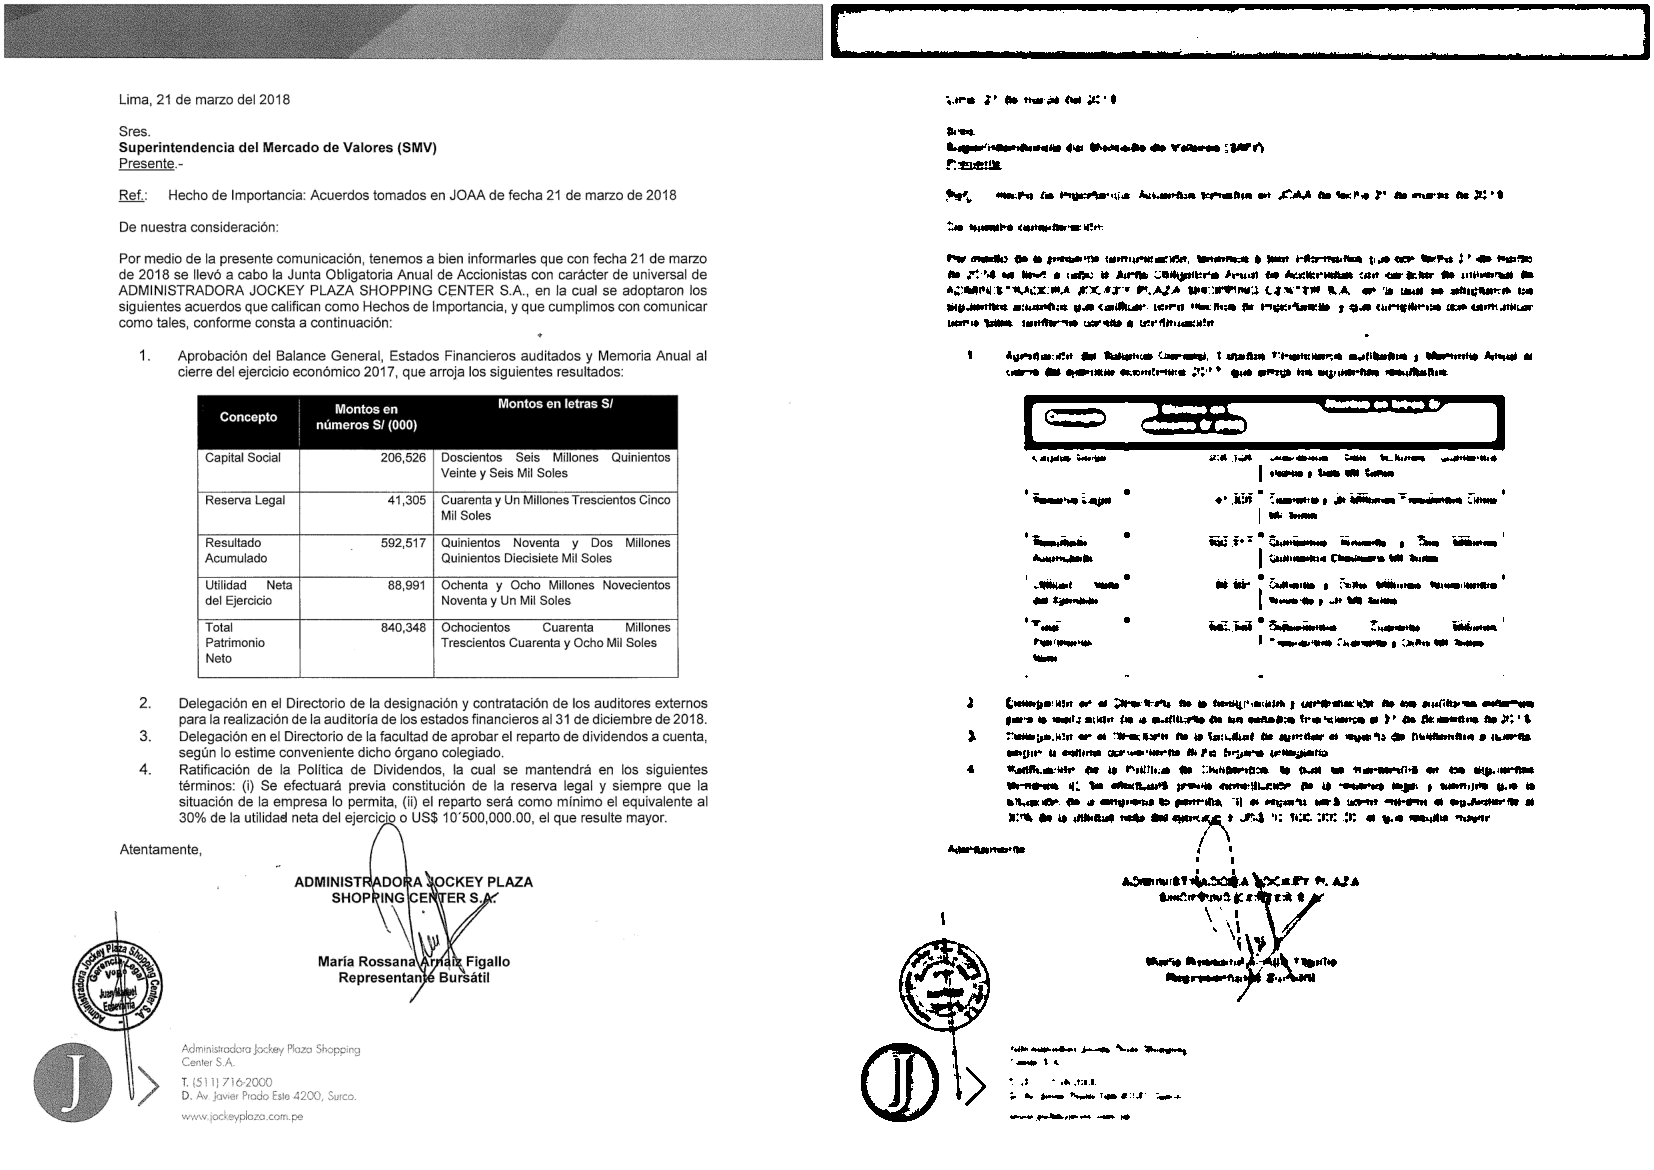

In [18]:
# Lote real (opcional): solo se mira el antes y el después, y se puntúa
import pymupdf
from IPython.display import display

REAL = DATOS / "14_Publico_Real"
if REAL.is_dir():
    filas = []
    for nombre in ("DIV-0006", "DIV-0007"):
        archivo = REAL / "01_Dividendos" / f"{nombre}.pdf"
        with pymupdf.open(str(archivo)) as pdf:
            paginas = len(pdf)
        for pagina in range(paginas):
            r = ejecutar(archivo, CFG, pagina=pagina)
            filas.append({"documento": nombre, "página": pagina + 1, "inclinación": r["inclinacion"], "confianza": round(r["confianza"], 3),
                          "campos válidos": r["puntaje"]["validos"], "inválidos": r["puntaje"]["invalidos"], "puntaje": r["puntaje"]["score"], "decisión": r["decision"]})
    print(pd.DataFrame(filas))
    antes = pdf_a_imagen(REAL / "01_Dividendos" / "DIV-0006.pdf", dpi=100)
    despues = aplicar_receta(corregir_inclinacion(antes)[0], OCR["receta"])
    display(Image.fromarray(np.hstack([a_gris(antes), despues])))
else:
    print("Sección opcional omitida: en esta máquina no hay carpeta '14_Publico_Real'.")

## Paso 8: E3, IoU de firma y sello (C5) y zonas de la página (C5b)

In [19]:
# E3: IoU de la firma y el sello detectados con OpenCV (salida calculada de antemano), control C5
from mi_pipeline.calidad.metricas import iou

caja_a, caja_b = (0, 0, 10, 10), (5, 0, 15, 10)
print("IoU a mano: zona común 50 / zona total 150 =", round(50 / 150, 3), "| con la función:", round(iou(caja_a, caja_b), 3))
assert abs(iou(caja_a, caja_b) - 50 / 150) < 1e-9

filas = []
for doc_id in OFICIOS:
    detectado = json.loads((DATOS / "11_Salidas_Precalculadas" / "ocr" / f"firma_sello_{doc_id}.json").read_text(encoding="utf-8"))
    correcto = {region["tipo"]: region["bbox"] for region in verdad(doc_id)["regiones"]}
    for region in detectado["regiones"]:
        filas.append({"documento": doc_id, "región": region["tipo"], "iou": round(iou(region["bbox"], correcto[region["tipo"]]), 3)})
tabla_iou = pd.DataFrame(filas).pivot(index="documento", columns="región", values="iou")
print(tabla_iou)
# ✔ Control C5
assert tabla_iou["sello"].min() > 0.85, "C5: el sello debe superar 0,85 de IoU en los cinco oficios."
assert (tabla_iou["firma"] >= 0.5).sum() >= 4, "C5: la firma debe llegar a 0,5 de IoU en al menos cuatro oficios."
CONTROLES.append("C5")
print(f"✔ C5 superado: IoU del sello {tabla_iou['sello'].min():.2f} a {tabla_iou['sello'].max():.2f}; la firma llega a 0,5 en {(tabla_iou['firma'] >= 0.5).sum()} de 5")

IoU a mano: zona común 50 / zona total 150 = 0.333 | con la función: 0.333
región     firma  sello
documento              
OFI-0001   0.626  0.901
OFI-0005   0.646  0.921
OFI-0012   0.575  0.931
OFI-0015   0.043  0.937
OFI-0016   0.677  0.945
✔ C5 superado: IoU del sello 0.90 a 0.94; la firma llega a 0,5 en 4 de 5


In [20]:
# E3: encabezado y pie por coordenadas, control C5b
from mi_pipeline.ocr.zonas import ZONAS, recortar_zona, zonas_de_pagina

MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "setiembre", "octubre", "noviembre", "diciembre"]


def normalizar(texto):
    """Minúsculas y espacios simples, para buscar un campo dentro de un texto leído."""
    return " ".join(texto.lower().split())


print("Zonas (fracciones de la altura):", {nombre: f"{desde:.2f} a {hasta:.2f}" for nombre, (desde, hasta) in ZONAS.items()})
filas = []
for doc_id in OFICIOS:
    pagina = aplicar_receta(cargar(doc_id), OCR["receta"])
    zonas = zonas_de_pagina(pagina)
    assert recortar_zona(pagina, *ZONAS["pie"]).shape == zonas["pie"].shape
    encabezado = normalizar(leer_texto(zonas["encabezado"]))
    pie = leer_con_confianza(zonas["pie"], OCR["lang"], OCR["oem"], OCR["psm"])
    campos = verdad(doc_id)["campos"]
    anio, mes, dia = campos["fecha"].split("-")
    filas.append({"documento": doc_id,
                  "emisor": normalizar(campos["emisor"]) in encabezado,
                  "número de oficio": "-".join(campos["numero_oficio"].split("-")[:2]) in encabezado,
                  "fecha": f"{int(dia)} de {MESES[int(mes) - 1]} de {anio}" in encabezado,
                  "palabras seguras en el pie": len([p for p in pie["palabras"] if p["conf"] >= 60 and len(p["texto"]) >= 3])})
tabla_zonas = pd.DataFrame(filas).set_index("documento")
print(tabla_zonas)
# ✔ Control C5b
assert tabla_zonas["emisor"].all(), "C5b: el emisor debe aparecer en el encabezado de los cinco oficios."
assert tabla_zonas["número de oficio"].sum() >= 4 and tabla_zonas["fecha"].sum() >= 4, "C5b: el número de oficio y la fecha deben aparecer en el encabezado de al menos cuatro oficios."
assert (tabla_zonas["palabras seguras en el pie"] == 0).all(), "C5b: el pie de estos oficios está en blanco."
CONTROLES.append("C5b")
print("✔ C5b superado: el encabezado trae emisor, número y fecha; el pie está en blanco")

Zonas (fracciones de la altura): {'encabezado': '0.00 a 0.22', 'cuerpo': '0.22 a 0.88', 'pie': '0.88 a 1.00'}
           emisor  número de oficio  fecha  palabras seguras en el pie
documento                                                             
OFI-0001     True              True   True                           0
OFI-0005     True              True   True                           0
OFI-0012     True             False  False                           0
OFI-0015     True              True   True                           0
OFI-0016     True              True   True                           0
✔ C5b superado: el encabezado trae emisor, número y fecha; el pie está en blanco


## Paso 9: E4: tabla de un estado financiero escaneado a DataFrame (C6)

In [21]:
# E4: tabla del balance de un estado financiero escaneado a DataFrame, control C6
from mi_pipeline.ocr.tablas import cuadratura, tabla_a_dataframe

filas, tablas = [], {}
for doc_id in ESTADOS:
    pagina = corregir_inclinacion(pdf_a_imagen(DATOS / "03_Estados_Financieros" / f"{doc_id}.pdf", dpi=OCR["dpi"]))[0]
    tablas[doc_id] = tabla_a_dataframe(pagina, OCR["lang"], OCR["oem"], OCR["psm"])
    c = cuadratura(tablas[doc_id], "2026")
    filas.append({"documento": doc_id, "filas": len(tablas[doc_id]), "total activo leído": c["activo"],
                  "total activo correcto": verdad(doc_id)["campos"]["total_activo"], "diferencia": c["diferencia"], "cuadra": c["cuadra"]})
print(tablas["EFI-0031"])
print()
print(pd.DataFrame(filas))
# ✔ Control C6
assert all(f["cuadra"] for f in filas), "C6: Activo = Pasivo + Patrimonio debe cumplirse en los tres estados financieros."
assert all(f["total activo leído"] == f["total activo correcto"] for f in filas), "C6: el total de activo leído debe coincidir con el correcto."
CONTROLES.append("C6")
print("✔ C6 superado: Activo = Pasivo + Patrimonio en las tres tablas extraídas")

                              Concepto     2026     2025
0                               ACTIVO      NaN      NaN
1                           Disponible   7113.0   5874.0
2                          Inversiones    355.0    391.0
3             Cartera de creditos neta   6402.0    391.0
4                   Cuentas por cobrar    355.0   3524.0
5       Inmuebles, mobiliario y equipo   6402.0   4307.0
6                        Otros activos  14942.0  24674.0
7                         Total activo  35569.0  39161.0
8                               PASIVO      NaN      NaN
9          Obligaciones con el publico   7080.0   7680.0
10  Adeudos y obligaciones financieras   8760.0   8760.0
11                   Cuentas por pagar   8520.0   5640.0
12                       Otros pasivos   5760.0  10440.0
13                        Total pasivo  30120.0  32520.0
14                          PATRIMONIO      NaN      NaN
15                      Capital social   3000.0   3000.0
16                            R

In [22]:
# E4: Tesseract frente a PaddleOCR (resultados guardados de cinco oficios y una tabla; la celda siguiente ejecuta PaddleOCR en vivo)
precalculadas = DATOS / "11_Salidas_Precalculadas" / "ocr"
filas = []
for doc_id in OFICIOS:
    archivo = precalculadas / f"paddle_texto_{doc_id}.json"
    if not archivo.is_file():
        continue
    paddle = json.loads(archivo.read_text(encoding="utf-8"))
    correcto = verdad(doc_id)["texto_completo"]
    tesseract = ejecutar(DATOS / "02_Oficios" / f"{doc_id}.pdf", CFG)
    filas.append({"documento": doc_id, "CER Tesseract": round(cer(correcto, tesseract["texto"]), 3),
                  "CER PaddleOCR": round(cer(correcto, paddle["texto"]), 3), "segundos de PaddleOCR (CPU)": paddle["segundos_prediccion"]})
if filas:
    comparacion = pd.DataFrame(filas).set_index("documento")
    print(comparacion)
    print("\nCER medio:", comparacion[["CER Tesseract", "CER PaddleOCR"]].mean().round(3).to_dict())
else:
    print("No hay salidas calculadas de antemano de PaddleOCR en esta máquina.")
tabla_paddle = precalculadas / "paddle_tabla_EFI-0031.json"
if tabla_paddle.is_file():
    resultado_paddle = json.loads(tabla_paddle.read_text(encoding="utf-8"))
    filas_html = [re.findall(r"<td[^>]*>(.*?)</td>", fila, flags=re.S) for fila in re.findall(r"<tr>(.*?)</tr>", resultado_paddle["tablas"][0]["html"], flags=re.S)]
    print(f"\nPaddleOCR (tabla de EFI-0031): {len(filas_html)} filas leídas en {resultado_paddle['segundos_prediccion'] / 60:.0f} minutos de CPU "
          f"| Tesseract + OpenCV: {len(tablas['EFI-0031']) + 1} filas (con encabezado) en pocos segundos")
    print([fila for fila in filas_html if fila and fila[0].lower().startswith("total")])

           CER Tesseract  CER PaddleOCR  segundos de PaddleOCR (CPU)
documento                                                           
OFI-0001           0.066          0.030                         21.6
OFI-0005           0.057          0.029                         21.3
OFI-0012           0.350          0.039                         19.9
OFI-0015           0.179          0.029                         21.7
OFI-0016           0.099          0.031                         20.8

CER medio: {'CER Tesseract': 0.15, 'CER PaddleOCR': 0.032}

PaddleOCR (tabla de EFI-0031): 22 filas leídas en 38 minutos de CPU | Tesseract + OpenCV: 22 filas (con encabezado) en pocos segundos
[['Totalactivo', '35,569', '39,161'], ['Total pasivo', '30,120', '32,520'], ['Total patrimonio', '5,449', '6,641'], ['Total pasivo y patrimonio', '35,569', '39,161']]


In [23]:
# E4: PaddleOCR en vivo sobre un oficio (CPU, modelos mobile; unos 30 segundos; la primera vez descarga 13 MB)
doc_id = "OFI-0001"
try:
    from paddleocr import PaddleOCR

    inicio = time.perf_counter()
    motor = PaddleOCR(text_detection_model_name="PP-OCRv5_mobile_det", text_recognition_model_name="latin_PP-OCRv5_mobile_rec",
                      use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False,
                      text_det_limit_side_len=2600, text_det_limit_type="max", enable_mkldnn=False)
    carga = time.perf_counter() - inicio
    pagina = corregir_inclinacion(pdf_a_imagen(DATOS / "02_Oficios" / f"{doc_id}.pdf", dpi=OCR["dpi"]))[0]
    inicio = time.perf_counter()
    lectura = motor.predict(np.ascontiguousarray(pagina[:, :, ::-1]))[0]
    segundos = time.perf_counter() - inicio
    texto_paddle = "\n".join(lectura["rec_texts"])
    print(f"Carga: {carga:.1f} s | lectura: {segundos:.1f} s | líneas: {len(lectura['rec_texts'])}")
    print("CER de PaddleOCR en vivo:", round(cer(verdad(doc_id)["texto_completo"], texto_paddle), 3))
    print(texto_paddle[:300])
except Exception as error:
    print("PaddleOCR no pudo ejecutarse en esta máquina:", error)
    print("La comparación de la celda anterior sigue siendo válida.")

C:\curso\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\curso\venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv5_mobile_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-OCRv5_mobile_det), the model files will be automatically downloaded and saved in `C:\Users\admin01\.paddlex\official_models\PP-OCRv5_mobile_det`.
Fetching 6 files: 100%|██████████| 6/6 [00:01<00:00,  6.00it/s]
Creating model: (

Carga: 11.5 s | lectura: 20.6 s | líneas: 29
CER de PaddleOCR en vivo: 0.03
AUTORIDAD SUPERVISORA DEMO
Intendencia DEMO de Riesgos Operacionales
Documento ficticio con fines de capacitacion
OFICIO N° 0230-2026-ID/DSF
Lima, 24 de junio de 2026
Senores
Aseguradora Nueva Aurora DEMO S.A.
RUC 20992371634
Presente.-
Asunto:
Solicitud de plan de accion para el cierre de observaci


## Lote público real (opcional): MEM-0002, página 47

In [24]:
# Lote real (opcional): página 47 de una memoria anual: la capa de texto del PDF es la referencia
if REAL.is_dir():
    memoria = REAL / "02_Memorias" / "MEM-0002.pdf"
    with pymupdf.open(str(memoria)) as pdf:
        referencia = pdf[46].get_text()
    r = ejecutar(memoria, CFG, pagina=46)
    print(f"CER frente a la capa de texto: {cer(referencia, r['texto']):.3f}, puntaje {r['puntaje']['score']}, decisión {r['decision']}")
    tabla_memoria = tabla_a_dataframe(corregir_inclinacion(pdf_a_imagen(memoria, pagina=46, dpi=OCR["dpi"]))[0], OCR["lang"], OCR["oem"], OCR["psm"])
    total = tabla_memoria[tabla_memoria["Concepto"].str.lower().str.startswith("total activo")]
    print(total)
    assert "72,952,708" in referencia and 72952708.0 in total.iloc[0, 1:].tolist(), "El total de activo leído debe coincidir con la capa de texto."
else:
    print("Sección opcional omitida: en esta máquina no hay carpeta '14_Publico_Real'.")

CER frente a la capa de texto: 0.009, puntaje 0.973, decisión aceptar
        Concepto     Valor 1     Valor 2
17  Total activo  72952708.0  67990143.0


## Reto extra (opcional)

In [25]:
# Reto extra (opcional): ¿psm 6 o psm 3 con la receta del YAML?
filas = {}
for doc_id in OFICIOS:
    imagen = aplicar_receta(cargar(doc_id), OCR["receta"])
    correcto = verdad(doc_id)["texto_completo"]
    filas[doc_id] = {f"psm {psm}": cer(correcto, pytesseract.image_to_string(imagen, lang=OCR["lang"], config=f"--oem {OCR['oem']} --psm {psm}")) for psm in (6, OCR["psm_pagina"])}
tabla_psm = pd.DataFrame(filas).T.round(3)
print(tabla_psm)
print("CER medio:", tabla_psm.mean().round(3).to_dict())

          psm 6  psm 3
OFI-0001  0.066  0.043
OFI-0005  0.057  0.069
OFI-0012  0.350  0.241
OFI-0015  0.179  0.148
OFI-0016  0.099  0.046
CER medio: {'psm 6': 0.15, 'psm 3': 0.109}


## Cierre

In [26]:
# ✔ Cierre: los controles y el tiempo del cuaderno
esperados = ["C0", "C1", "C2", "C3", "C4", "C5", "C5b", "C6"]
faltan = [c for c in esperados if c not in CONTROLES]
assert not faltan, f"Faltan controles por superar: {faltan}"
print("✔ Controles superados:", ", ".join(CONTROLES))
print(f"Tiempo del cuaderno: {(time.perf_counter() - INICIO) / 60:.1f} minutos")
print("Siguiente: guardar el avance (commit) y subir la rama, como indica la guía.")

✔ Controles superados: C0, C1, C2, C3, C4, C5, C5b, C6
Tiempo del cuaderno: 75.4 minutos
Siguiente: guardar el avance (commit) y subir la rama, como indica la guía.
